# Checkpoint 3 — Clustering aplicado à energia

**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Nome e RM:** Gabriel Rodrigues Zappelloni — RM 572060  
**Turma:** 1CCPK

## Situação-problema

Uma equipe de gestão de energia quer conhecer os diferentes perfis de uso de suas unidades consumidoras para planejar ações de acompanhamento e uso consciente de energia. Cada registro reúne informações de uma unidade no mesmo mês de referência.

Seu desafio é identificar grupos de unidades com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 unidades consumidoras fictícias**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de medidores, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_unidade` | Identificador da unidade consumidora | Identificação; excluir do modelo |
| `consumo_mensal_kwh` | Energia total consumida no mês | kWh |
| `demanda_maxima_kw` | Maior demanda de potência média registrada em uma janela de 15 minutos no mês | kW |
| `consumo_noturno_pct` | Parcela da energia mensal consumida entre 18h e 6h | % entre 0 e 100 |

Energia, em kWh, representa o consumo acumulado; potência, em kW, representa a taxa de uso de energia. O percentual noturno descreve o horário de consumo. Nenhuma dessas variáveis, isoladamente, permite afirmar que uma unidade desperdiça energia ou que paga uma tarifa maior.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook
DADOS_CSV = """
id_unidade,consumo_mensal_kwh,demanda_maxima_kw,consumo_noturno_pct
UC001,791.43,7.28,23.95
UC002,1349.44,6.65,72.17
UC003,1355.67,6.5,76.47
UC004,209.34,0.5,67.76
UC005,1675.8,5.99,78.53
UC006,259.28,3.13,59.3
UC007,180.39,3.38,61.37
UC008,1705.73,8.78,76.28
UC009,1421.17,6.34,66.16
UC010,769.67,8.28,13.51
UC011,1003.9,6.81,24.07
UC012,1136.69,5.5,39.81
UC013,1237.83,5.41,28.87
UC014,1358.74,4.78,26.72
UC015,696.34,7.57,32.59
UC016,330.75,1.83,64.99
UC017,1448.43,6.91,69.18
UC018,1559.32,4.87,75.15
UC019,208.86,2.98,79.31
UC020,1340.84,5.18,51.64
UC021,1666.35,6.22,54.65
UC022,684.26,7.29,21.61
UC023,1858.04,6.28,57.13
UC024,1548.18,5.13,76.59
UC025,1286.54,7.4,70.44
UC026,671.62,6.18,27.59
UC027,286.11,1.74,71.6
UC028,306.77,2.73,70.48
UC029,191.95,2.71,46.75
UC030,160.72,3.07,46.56
UC031,1914.05,6.29,67.69
UC032,639.82,5.55,22.34
UC033,1343.78,5.82,71.13
UC034,199.73,2.95,66.44
UC035,1466.32,6.83,59.17
UC036,166.38,2.19,58.04
UC037,754.59,11.69,30.64
UC038,256.47,1.57,61.37
UC039,1440.36,5.28,72.3
UC040,1112.84,10.02,30.37
UC041,1325.72,7.23,65.96
UC042,1244.96,7.05,61.76
UC043,1580.58,8.86,61.86
UC044,288.92,3.5,48.41
UC045,1413.1,5.86,73.32
UC046,1243.79,9.36,74.18
UC047,1018.37,8.09,16.74
UC048,889.65,7.82,20.83
UC049,293.69,2.78,49.17
UC050,239.89,2.61,50.72
UC051,1149.27,4.41,69.7
UC052,903.31,6.04,47.47
UC053,1447.32,7.0,60.31
UC054,324.49,3.43,57.92
UC055,975.35,7.83,24.91
UC056,253.75,3.19,47.61
UC057,185.26,2.79,60.37
UC058,275.33,2.06,76.62
UC059,1173.41,8.29,27.67
UC060,336.68,1.44,61.73
UC061,1472.11,5.42,56.01
UC062,1420.31,5.76,69.66
UC063,1066.74,7.03,8.35
UC064,1206.7,4.49,65.74
UC065,301.5,2.46,62.06
UC066,471.96,4.72,22.2
UC067,793.83,6.47,39.74
UC068,814.11,8.18,20.03
UC069,1083.2,6.04,24.84
UC070,835.44,8.55,26.43
UC071,191.85,1.84,50.14
UC072,541.54,5.65,23.23
UC073,266.76,2.93,58.84
UC074,234.77,3.06,73.52
UC075,1070.5,6.15,25.14
UC076,1270.27,3.3,71.85
UC077,212.02,2.76,59.79
UC078,1426.91,6.37,54.31
UC079,226.26,2.13,63.17
UC080,130.01,2.74,56.49
UC081,695.66,3.84,37.71
UC082,1599.27,5.34,49.98
UC083,1357.57,3.68,74.87
UC084,1373.33,6.77,90.34
UC085,504.17,6.68,39.48
UC086,328.86,3.42,65.21
UC087,1134.59,7.04,73.45
UC088,194.57,2.38,72.45
UC089,945.97,5.09,17.76
UC090,1441.73,6.74,44.47
UC091,1524.46,6.97,78.07
UC092,714.84,8.2,13.75
UC093,1379.84,6.47,64.98
UC094,1108.56,5.36,64.45
UC095,210.07,2.21,54.13
UC096,1174.74,5.89,18.89
UC097,644.55,6.99,27.88
UC098,208.74,2.93,67.23
UC099,1873.16,4.36,64.23
UC100,1138.21,7.79,24.51
UC101,270.96,2.2,62.31
UC102,784.72,9.76,32.76
UC103,1237.88,4.97,79.03
UC104,841.88,7.37,15.06
UC105,1362.73,3.61,63.05
UC106,666.95,7.15,17.58
UC107,1136.73,2.2,26.42
UC108,222.53,2.76,69.93
UC109,206.28,2.32,43.43
UC110,197.03,3.69,59.72
UC111,294.74,2.25,70.32
UC112,319.74,2.93,55.82
UC113,379.07,2.13,61.4
UC114,305.26,3.2,52.56
UC115,868.46,7.37,24.69
UC116,147.71,2.36,67.72
UC117,606.83,6.35,21.84
UC118,1382.92,9.14,68.61
UC119,967.14,7.18,29.84
UC120,874.2,5.62,21.92
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Unidades consumidoras: {len(df)}")


id_unidade  consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
     UC001              791.43               7.28                23.95
     UC002             1349.44               6.65                72.17
     UC003             1355.67               6.50                76.47
     UC004              209.34               0.50                67.76
     UC005             1675.80               5.99                78.53
Unidades consumidoras: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o consumo mensal poderia esconder diferenças de comportamento?


In [3]:
# Tamanho da base e tipos das colunas
print("Formato (linhas, colunas):", df.shape)
print()
df.info()

# Valores ausentes por coluna
print("\nValores ausentes por coluna:")
print(df.isna().sum())

# Identificadores repetidos
print("\nIdentificadores repetidos:", df["id_unidade"].duplicated().sum())

# Estatísticas descritivas das três variáveis numéricas
variaveis = ["consumo_mensal_kwh", "demanda_maxima_kw", "consumo_noturno_pct"]
descricao = df[variaveis].describe().T
descricao["amplitude"] = descricao["max"] - descricao["min"]
descricao.round(2)

Formato (linhas, colunas): (120, 4)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_unidade           120 non-null    object 
 1   consumo_mensal_kwh   120 non-null    float64
 2   demanda_maxima_kw    120 non-null    float64
 3   consumo_noturno_pct  120 non-null    float64
dtypes: float64(3), object(1)
memory usage: 3.9+ KB

Valores ausentes por coluna:
id_unidade             0
consumo_mensal_kwh     0
demanda_maxima_kw      0
consumo_noturno_pct    0
dtype: int64

Identificadores repetidos: 0


,count,mean,std,min,25%,50%,75%,max,amplitude
consumo_mensal_kwh,120.0,851.84,516.24,130.01,294.48,855.17,1341.57,1914.05,1784.04
demanda_maxima_kw,120.0,5.20,2.30,0.50,2.97,5.46,6.98,11.69,11.19
consumo_noturno_pct,120.0,51.23,20.39,8.35,29.60,57.98,67.73,90.34,81.99


**Resposta e observações:**

- A base tem **120 linhas e 4 colunas**: `id_unidade` (texto) e três variáveis numéricas (`float64`). **Não há valores ausentes** e **nenhum identificador se repete**, então cada linha é uma unidade consumidora diferente.
- **Amplitudes** (máximo − mínimo):
  - `consumo_mensal_kwh`: de 130,01 a 1.914,05 kWh → amplitude de **1.784,04 kWh** (média 851,84; desvio padrão 516,24).
  - `consumo_noturno_pct`: de 8,35% a 90,34% → amplitude de **81,99 pontos percentuais** (média 51,23; desvio 20,39).
  - `demanda_maxima_kw`: de 0,50 a 11,69 kW → amplitude de **11,19 kW** (média 5,20; desvio 2,30).
- Em valor absoluto, o **consumo mensal** tem de longe a maior amplitude, seguido do percentual noturno. A demanda tem a menor amplitude numérica, mas isso é efeito da unidade (kW), não significa que ela varie pouco: o máximo é mais de 20 vezes o mínimo.
- **Por que usar só o consumo mensal esconderia diferenças:** duas unidades com o mesmo consumo podem ter comportamentos muito diferentes. Por exemplo, UC014 (1.358,74 kWh; 26,7% noturno) e UC083 (1.357,57 kWh; 74,9% noturno) consomem praticamente o mesmo, mas uma usa energia principalmente de dia e a outra à noite. Da mesma forma, uma unidade pode ter consumo moderado e picos de potência altos (demanda), o que exige ações diferentes. O consumo diz *quanto* se usa; a demanda diz *com que intensidade* e o percentual noturno diz *quando*.

## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_unidade` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [4]:
# Seleção das três variáveis numéricas (sem id_unidade)
variaveis = ["consumo_mensal_kwh", "demanda_maxima_kw", "consumo_noturno_pct"]
X = df[variaveis]

# Padronização: (valor - média) / desvio padrão
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)

# Inspeção: depois da padronização, cada variável tem média ~0 e desvio ~1
X_padronizado_df = pd.DataFrame(X_padronizado, columns=variaveis)
print("Primeiras linhas padronizadas:")
print(X_padronizado_df.head().round(3).to_string(index=False))
print("\nMédia e desvio padrão após a padronização:")
print(X_padronizado_df.agg(["mean", "std"]).round(3))

# df continua nas unidades originais
print("\ndf não foi alterado:")
print(df.head(3).to_string(index=False))

Primeiras linhas padronizadas:
 consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
             -0.118              0.907               -1.343
              0.968              0.633                1.031
              0.980              0.567                1.243
             -1.250             -2.051                0.814
              1.603              0.345                1.344

Média e desvio padrão após a padronização:
      consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
mean              -0.000             -0.000               -0.000
std                1.004              1.004                1.004

df não foi alterado:
id_unidade  consumo_mensal_kwh  demanda_maxima_kw  consumo_noturno_pct
     UC001              791.43               7.28                23.95
     UC002             1349.44               6.65                72.17
     UC003             1355.67               6.50                76.47


**Justificativa da padronização:**

O K-Means agrupa pelos **quadrados das distâncias euclidianas**. Sem padronizar, cada variável entra na distância na sua unidade original: o consumo varia na casa das centenas de kWh (desvio padrão de 516,24), enquanto a demanda varia em poucos kW (desvio de 2,30). Uma diferença de 100 kWh pesaria muito mais do que uma diferença de 5 kW, embora 5 kW seja uma diferença grande de demanda. Na prática, o modelo agruparia quase só pelo consumo e ignoraria a demanda e o horário de uso.

O `StandardScaler` subtrai a média e divide pelo desvio padrão de cada variável. Depois disso, as três têm **média 0 e desvio padrão 1**, como mostra a saída acima (o pandas mostra 1,004 porque calcula o desvio com n − 1, enquanto o `StandardScaler` usa n). Cada valor passa a indicar quantos desvios padrão a unidade está acima ou abaixo da média. Assim, as três variáveis contribuem de forma comparável para as distâncias. Ele **não** coloca os dados entre 0 e 1: os valores padronizados podem ser negativos ou maiores que 1.

`id_unidade` ficou de fora porque é só um rótulo e não descreve comportamento. O `df` original foi preservado para interpretar os grupos em kWh, kW e %.

## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, consumos de 100, 120 e 140 kWh formam um grupo com centroide de 120 kWh. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800\;\mathrm{kWh}^2$$

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa kWh consumidos. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


 k  inercia  queda_em_relacao_ao_k_anterior
 1   360.00                             NaN
 2   184.70                          175.30
 3    74.25                          110.44
 4    61.10                           13.15
 5    52.06                            9.04
 6    46.36                            5.70
 7    40.90                            5.47
 8    37.25                            3.65


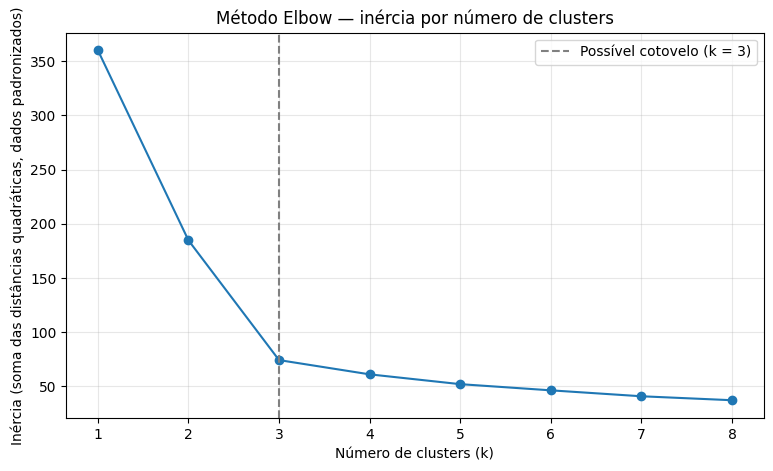

In [5]:
# Inércia para k de 1 a 8
valores_k = range(1, 9)
distorcoes = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

tabela_elbow = pd.DataFrame({"k": list(valores_k), "inercia": distorcoes})
tabela_elbow["queda_em_relacao_ao_k_anterior"] = -tabela_elbow["inercia"].diff()
print(tabela_elbow.round(2).to_string(index=False))

plt.plot(list(valores_k), distorcoes, marker="o")
plt.axvline(3, color="gray", linestyle="--", label="Possível cotovelo (k = 3)")
plt.title("Método Elbow — inércia por número de clusters")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia (soma das distâncias quadráticas, dados padronizados)")
plt.xticks(list(valores_k))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Leitura do Elbow:**

| k | Inércia | Queda em relação ao k anterior |
| --- | ---: | ---: |
| 1 | 360,00 | — |
| 2 | 184,70 | 175,30 |
| 3 | 74,25 | 110,44 |
| 4 | 61,10 | 13,15 |
| 5 | 52,06 | 9,04 |
| 6 | 46,36 | 5,70 |
| 7 | 40,90 | 5,47 |
| 8 | 37,25 | 3,65 |

Com k = 1, a inércia é 360 (120 unidades × 3 variáveis padronizadas). As duas primeiras quedas são grandes: 175,30 de k = 1 para 2 e 110,44 de k = 2 para 3. A partir de k = 3, a curva achata: passar de 3 para 4 reduz só 13,15, e as quedas seguintes ficam entre 9 e 4.

A **região candidata ao cotovelo é k = 3**. Até 3 grupos, cada novo cluster separa comportamentos realmente diferentes. Depois disso, criar mais grupos reduz pouco a inércia, porque estaria dividindo grupos que já são compactos. O Elbow sozinho não decide; essa indicação será comparada com o Silhouette Score.

## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


 k  silhouette_score
 2            0.4835
 3            0.6031
 4            0.5190
 5            0.4282
 6            0.4343
 7            0.3240
 8            0.3106

Maior Silhouette Score: k = 3 (score = 0.6031)


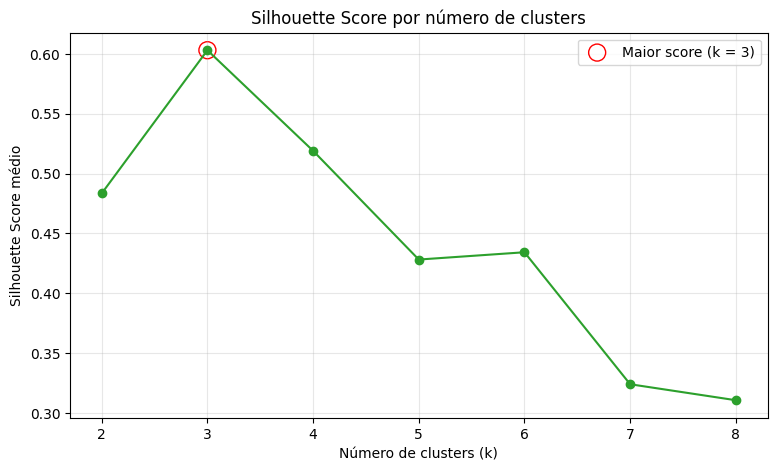

In [6]:
# Silhouette Score para k de 2 a 8
resultados_silhouette = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)
    score = silhouette_score(X_padronizado, rotulos)
    resultados_silhouette.append({"k": k, "silhouette_score": score})

tabela_silhouette = pd.DataFrame(resultados_silhouette)
print(tabela_silhouette.round(4).to_string(index=False))

melhor = tabela_silhouette.loc[tabela_silhouette["silhouette_score"].idxmax()]
print(f"\nMaior Silhouette Score: k = {int(melhor['k'])} (score = {melhor['silhouette_score']:.4f})")

plt.plot(tabela_silhouette["k"], tabela_silhouette["silhouette_score"], marker="o", color="tab:green")
plt.scatter(melhor["k"], melhor["silhouette_score"], s=150, facecolors="none", edgecolors="red",
            label=f"Maior score (k = {int(melhor['k'])})")
plt.title("Silhouette Score por número de clusters")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score médio")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Comparação das evidências:**

| k | Silhouette Score |
| --- | ---: |
| 2 | 0,4835 |
| **3** | **0,6031** |
| 4 | 0,5190 |
| 5 | 0,4282 |
| 6 | 0,4343 |
| 7 | 0,3240 |
| 8 | 0,3106 |

O **maior Silhouette Score do intervalo é 0,6031, com k = 3**. O valor sobe de k = 2 (0,4835) para k = 3 e depois cai: 0,5190 com k = 4 e menos de 0,44 de k = 5 em diante. Ou seja, com 3 grupos as unidades estão, em média, bem mais próximas do próprio grupo do que do grupo vizinho. Ao criar mais grupos, passam a surgir fronteiras artificiais entre pontos parecidos.

**Não há divergência:** o Elbow indicou k = 3 (a última queda grande da inércia, de 184,70 para 74,25) e o Silhouette também tem o seu máximo em k = 3. As duas evidências apontam para a mesma escolha.

Também testei a interpretação: com k = 4, os grupos de baixo consumo e de alto consumo noturno continuam iguais, e o grupo de consumo diurno é apenas dividido em dois subgrupos com médias muito próximas (cerca de 873 e 880 kWh, 23% e 28% noturno). Essa divisão não gera um perfil novo com uma ação de gestão diferente, o que reforça k = 3.

## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de unidades por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [7]:
# Modelo final
k_escolhido = 3

modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)

# Cópia de df com a coluna cluster (X e X_padronizado não são alterados)
df_resultados = df.copy()
df_resultados["cluster"] = rotulos_finais

print("Unidades por cluster:")
print(df_resultados["cluster"].value_counts().sort_index().to_string())

score_final = silhouette_score(X_padronizado, rotulos_finais)
print(f"\nSilhouette Score final (k = {k_escolhido}): {score_final:.4f}")
print(f"Inércia final: {modelo_final.inertia_:.2f}")

Unidades por cluster:
cluster
0    40
1    40
2    40

Silhouette Score final (k = 3): 0.6031
Inércia final: 74.25


**k escolhido e justificativa:**

Escolhi **k = 3** porque as três evidências concordam:

1. **Elbow:** k = 3 é o cotovelo. A inércia cai de 360,00 para 74,25 até k = 3; a partir daí, cada cluster extra reduz no máximo 13,15.
2. **Silhouette:** k = 3 tem o maior score do intervalo, 0,6031, contra 0,5190 em k = 4 e 0,4835 em k = 2.
3. **Interpretação:** os 3 grupos têm perfis distintos e fáceis de explicar (seção 7). Com k = 4, um desses perfis é apenas dividido em dois subgrupos quase iguais.

O modelo final dividiu as 120 unidades em **3 grupos de 40 unidades cada** e manteve o Silhouette Score de **0,6031**. A coluna `cluster` foi colocada só em `df_resultados`; `X` e `X_padronizado` continuam sem ela.

## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Consumo mensal × demanda máxima.
2. Consumo mensal × percentual de consumo noturno.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de unidades e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de gestão de energia para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Consumo alto não prova desperdício. Uma recomendação sobre tarifa ou geração solar exigiria dados adicionais de contrato, horários, local e viabilidade.


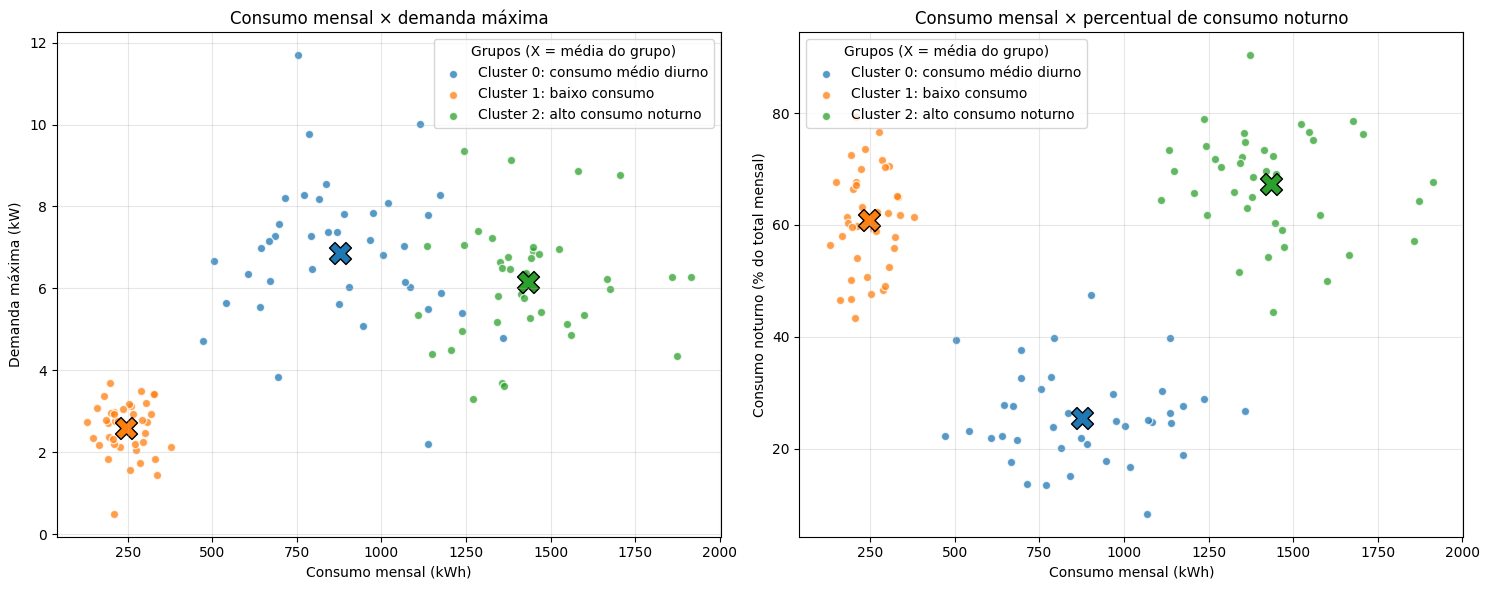

In [8]:
# Nomes descritivos para a legenda (definidos a partir da tabela de perfis abaixo)
medias = df_resultados.groupby("cluster")[variaveis].mean()
nomes_clusters = {}
for c, linha in medias.iterrows():
    if linha["consumo_mensal_kwh"] < 500:
        nomes_clusters[c] = f"Cluster {c}: baixo consumo"
    elif linha["consumo_noturno_pct"] < 40:
        nomes_clusters[c] = f"Cluster {c}: consumo médio diurno"
    else:
        nomes_clusters[c] = f"Cluster {c}: alto consumo noturno"

cores = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
fig, eixos = plt.subplots(1, 2, figsize=(15, 6))

graficos = [
    ("demanda_maxima_kw", "Demanda máxima (kW)", "Consumo mensal × demanda máxima"),
    ("consumo_noturno_pct", "Consumo noturno (% do total mensal)", "Consumo mensal × percentual de consumo noturno"),
]

for eixo, (coluna_y, rotulo_y, titulo) in zip(eixos, graficos):
    for c in sorted(df_resultados["cluster"].unique()):
        grupo = df_resultados[df_resultados["cluster"] == c]
        eixo.scatter(grupo["consumo_mensal_kwh"], grupo[coluna_y],
                     color=cores[c], alpha=0.75, edgecolors="white", label=nomes_clusters[c])
        eixo.scatter(medias.loc[c, "consumo_mensal_kwh"], medias.loc[c, coluna_y],
                     color=cores[c], marker="X", s=250, edgecolors="black")
    eixo.set_title(titulo)
    eixo.set_xlabel("Consumo mensal (kWh)")
    eixo.set_ylabel(rotulo_y)
    eixo.grid(alpha=0.3)
    eixo.legend(title="Grupos (X = média do grupo)")

plt.tight_layout()
plt.show()

In [9]:
# Tabela de perfis por cluster, nas unidades originais
perfis = df_resultados.groupby("cluster").agg(
    unidades=("id_unidade", "count"),
    consumo_medio_kwh=("consumo_mensal_kwh", "mean"),
    demanda_media_kw=("demanda_maxima_kw", "mean"),
    noturno_medio_pct=("consumo_noturno_pct", "mean"),
)
perfis["perfil"] = perfis.index.map(nomes_clusters)
print(perfis.round(2).to_string())

# Faixas (mínimo e máximo) de cada variável por grupo, para apoiar a interpretação
print("\nFaixas por cluster:")
df_resultados.groupby("cluster")[variaveis].agg(["min", "max"]).round(2)

         unidades  consumo_medio_kwh  demanda_media_kw  noturno_medio_pct                           perfil
cluster                                                                                                   
0              40             876.50              6.87              25.49  Cluster 0: consumo médio diurno
1              40             245.09              2.58              60.82         Cluster 1: baixo consumo
2              40            1433.93              6.15              67.37  Cluster 2: alto consumo noturno

Faixas por cluster:


consumo_mensal_kwh          demanda_maxima_kw         \
                       min      max               min    max   
cluster                                                        
0                   471.96  1358.74               2.2  11.69   
1                   130.01   379.07               0.5   3.69   
2                  1108.56  1914.05               3.3   9.36   

        consumo_noturno_pct         
                        min    max  
cluster                             
0                      8.35  47.47  
1                     43.43  79.31  
2                     44.47  90.34

**Interpretação dos perfis e ações propostas:**

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| **0 — consumo médio, uso diurno e picos de potência** | 40 unidades. Consumo médio de **876,50 kWh** (de 471,96 a 1.358,74), a **maior demanda média, 6,87 kW** (até 11,69 kW), e só **25,49% do consumo à noite** (de 8,35% a 47,47%). Usam energia principalmente de dia e com picos de potência altos em relação ao consumo. | Acompanhar a demanda: identificar quais equipamentos são ligados ao mesmo tempo e **escalonar o acionamento de cargas grandes** (climatização, motores, máquinas) para reduzir os picos. Orientar o uso consciente no horário de funcionamento. | Curva de carga em intervalos de 15 minutos, horário de funcionamento, lista de equipamentos e, se houver, demanda contratada, para saber se os picos geram custo extra. |
| **1 — baixo consumo** | 40 unidades. Consumo médio de **245,09 kWh** (de 130,01 a 379,07), demanda média de **2,58 kW** (no máximo 3,69) e **60,82% do consumo à noite**. É o grupo mais compacto (silhouette médio de 0,757). | **Acompanhamento simples e de baixo custo:** comunicados de uso consciente e alerta automático se o consumo mensal subir muito em relação ao histórico. Não é prioridade para auditoria. | Tipo de unidade (residencial, escritório pequeno, etc.), número de ocupantes e histórico de vários meses, para confirmar se o consumo baixo é estável. |
| **2 — alto consumo, concentrado à noite** | 40 unidades. **Maior consumo médio, 1.433,93 kWh** (de 1.108,56 a 1.914,05), demanda média de **6,15 kW** e **67,37% do consumo à noite** (chega a 90,34%). Consomem muito e principalmente entre 18h e 6h. | **Prioridade de acompanhamento:** visitas técnicas ou auditoria energética para identificar as cargas noturnas (iluminação, climatização, equipamentos que ficam ligados) e verificar se são necessárias. Se houver equipamentos ligados sem uso, programar o desligamento. | Se a unidade opera à noite (turno noturno, operação 24h), quais equipamentos ficam ligados, tipo de tarifa e contrato. Só com esses dados daria para avaliar tarifa horária ou outras medidas. |

**O que os dados mostram e o que ainda precisa ser investigado:**
- Os dados mostram **quanto** cada unidade consome, o **pico de potência** e **em que período** consome. Isso basta para separar os três perfis.
- Os dados **não** mostram desperdício. Um consumo alto, como no cluster 2, pode ser necessário, por exemplo numa unidade que funciona 24 horas. Também não dá para recomendar mudança de tarifa ou geração solar sem dados de contrato, horários, localização e viabilidade.
- Os gráficos mostram projeções em 2 dimensões, mas o modelo usou as 3 variáveis. No gráfico de consumo × demanda, os clusters 0 e 2 se sobrepõem um pouco; a separação aparece no gráfico de consumo noturno, que é o que mais distingue esses dois grupos.
- Algumas unidades ficam na fronteira entre grupos. Por exemplo, UC081 (695,66 kWh; 3,84 kW; 37,71% noturno) tem silhouette individual levemente negativo, então a classificação dela é menos segura.

## 8. Conclusão — 1,0 ponto

Responda com base nos seus resultados:

1. Como o agrupamento ajuda a equipe de gestão de energia?
2. Por que o menor valor de inércia, isoladamente, não resolve a escolha de k?
3. Por que Silhouette Score não é uma medida de acurácia?
4. Por que é necessário separar as variáveis usadas no modelo da coluna `cluster`?
5. Apresente pelo menos duas limitações: uma sobre a base simulada e outra sobre os dados disponíveis ou o K-Means. Que dados reais você buscaria para aprimorar a análise?

**Conclusão:**

1. **Como o agrupamento ajuda:** em vez de analisar 120 unidades uma por uma, a equipe passa a trabalhar com **3 perfis de 40 unidades**, cada um com uma ação própria: controle de picos de demanda no cluster 0 (consumo médio diurno), acompanhamento simples no cluster 1 (baixo consumo) e prioridade de auditoria no cluster 2 (alto consumo noturno, média de 1.433,93 kWh). Assim, ela concentra o esforço onde o consumo é maior e escolhe ações adequadas a cada comportamento.

2. **Por que a menor inércia não basta:** a inércia sempre diminui quando k aumenta. Com k = 120, cada unidade seria o seu próprio grupo e a inércia seria zero, mas isso não teria utilidade. Aqui, ela caiu de 74,25 (k = 3) para 37,25 (k = 8), sem que os grupos extras representassem perfis novos. Por isso, o que importa é onde a queda deixa de valer a pena (o cotovelo em k = 3), confirmado pelo Silhouette Score.

3. **Por que o Silhouette não é acurácia:** acurácia compara previsões com respostas corretas, e esta base **não tem uma classificação correta**. O Silhouette só mede, usando as distâncias, o quanto cada ponto está mais perto do próprio grupo do que do grupo vizinho. O score de 0,6031 indica grupos bem separados nesse espaço padronizado. Ele **não** significa que 60% das unidades foram classificadas corretamente.

4. **Por que separar as variáveis do modelo da coluna `cluster`:** a coluna `cluster` é o **resultado** do modelo, não uma característica da unidade. Se ela entrasse em `X_padronizado`, viraria uma quarta dimensão das distâncias. Pontos do mesmo grupo ficariam artificialmente mais próximos, e o Silhouette Score ficaria inflado. Ou seja, o modelo estaria sendo avaliado usando a própria resposta. Por isso, os rótulos ficaram só em `df_resultados`.

5. **Limitações e dados reais:**
   - **Base simulada:** as 120 unidades foram geradas com NumPy (semente 303) e não vieram de medidores reais. Os 3 grupos de exatamente 40 unidades sugerem que a base foi criada com três perfis bem definidos. Dados reais costumam ter grupos de tamanhos diferentes, ruído e valores atípicos.
   - **Dados disponíveis:** temos só **um mês** e **três variáveis**. Não há sazonalidade, tipo de unidade, área, número de ocupantes, horário de funcionamento nem contrato e tarifa. Então dá para descrever perfis, mas não para afirmar desperdício nem recomendar mudança de tarifa.
   - **K-Means:** exige escolher k antes, supõe grupos aproximadamente esféricos e de tamanhos parecidos, e é sensível a valores extremos e à inicialização. Para reduzir esse último ponto, usei `n_init=10` e `random_state=42`. Unidades na fronteira, como a UC081, podem mudar de grupo com pequenas variações nos dados.
   - **Dados reais que eu buscaria:** histórico de **12 meses ou mais** (sazonalidade), **curvas de carga em intervalos de 15 minutos**, tipo e atividade da unidade, área e ocupação, horário de funcionamento, **demanda contratada e modalidade tarifária**, inventário de equipamentos e dados de temperatura. Com isso, daria para confirmar os perfis e avaliar ações como mudança de tarifa ou geração solar.

## Entrega e critérios de avaliação

Entregue o **notebook `.ipynb` preenchido e executado**, contendo identificação, códigos, tabelas, gráficos, justificativas e conclusões. A base está incorporada; não é necessário um arquivo externo para executar a atividade. Prazo e canal de entrega serão definidos pelo professor.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,0 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.








### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade inspirada na sequência do notebook de referência fornecido pelo professor, com nova base de energia e cuidados adicionais na seleção e avaliação das variáveis.
